# Counting baskets or counting buyers?
**Deliverable 2 · Retail analytics | Akhil Kamatam and Snehith Reddy**

When a shopper selects one item, what three other products should a retailer suggest? A pair that appears on 20 invoices from one buyer has different evidence behind it than a pair bought by 15 different buyers. This notebook tests whether the number of distinct buyers adds information beyond invoice frequency.

**Run in Colab:** Upload this notebook, select a standard CPU runtime, then **Runtime → Run all**. The first run downloads the original UCI workbook. No separate dataset upload, drive mount, API key, GPU, or Dask cluster is needed. The spreadsheet import can take a few minutes.

**Reading the output:** A basket is one invoice; a buyer is one nonmissing customer ID. A “hit” means at least one of three recommendations matches another item actually purchased on a held-out invoice. It does not mean the recommendation caused a sale.

## 1 · Load and inspect the public dataset
The source is Daqing Chen's [Online Retail dataset at UCI](https://doi.org/10.24432/C5BW33), a UK gift retailer's records from December 2010 to December 2011. Each row is an invoice **line**, not an order. Read identifiers as text. Inspect the actual workbook rather than assuming that every identifier or description is present.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
from collections import Counter
from itertools import combinations
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

SEED = 42
HISTORY_END = pd.Timestamp("2011-06-01")   # exclusive
FIT_END = pd.Timestamp("2011-09-01")       # exclusive
CATALOG_SIZE = 500
MIN_PAIR_INVOICES = 3
K = 3
sns.set_theme(style="whitegrid", context="notebook")
TEAL, BLUE, GRAY = "#176b66", "#254c73", "#596673"
print("Python", platform.python_version(), "| pandas", pd.__version__, "| NumPy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| Matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__)

Python 3.12.14 | pandas 2.2.3 | NumPy 2.3.5 | scikit-learn 1.8.0 | Matplotlib 3.10.8 | seaborn 0.13.2


In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
CACHE = Path("uci_retail.zip")
EXPECTED_SHA = "f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b"

# Reuse only a byte-identical copy of the public archive in this runtime.
archive = CACHE.read_bytes() if CACHE.exists() else b""
if hashlib.sha256(archive).hexdigest() != EXPECTED_SHA:
    with urlopen(DATA_URL, timeout=120) as response:
        archive = response.read()
    if hashlib.sha256(archive).hexdigest() != EXPECTED_SHA:
        raise ValueError("The UCI archive has changed. Verify the source before updating the checksum.")
    CACHE.write_bytes(archive)
with ZipFile(BytesIO(archive)) as book:
    with book.open("Online Retail.xlsx") as sheet:
        raw = pd.read_excel(sheet, engine="openpyxl",
                            dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"})
del archive
required = {"InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
            "UnitPrice", "CustomerID", "Country"}
assert required == set(raw.columns)
print(f"{len(raw):,} invoice lines × {raw.shape[1]} columns")
print("Recorded period:", raw.InvoiceDate.min(), "to", raw.InvoiceDate.max())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                      "distinct_nonmissing": raw.nunique()}))
display(raw[["Description", "Quantity", "UnitPrice", "Country"]].head(3))

541,909 invoice lines × 8 columns
Recorded period: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,dtype,missing,distinct_nonmissing
InvoiceNo,string,0,25900
StockCode,string,0,4070
Description,object,1454,4223
Quantity,int64,0,722
InvoiceDate,datetime64[ns],0,23260
UnitPrice,float64,0,1630
CustomerID,string,135080,4372
Country,object,0,38


,Description,Quantity,UnitPrice,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,United Kingdom
1,WHITE METAL LANTERN,6,3.39,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,United Kingdom


## 2 · Clean merchandise lines and reconstruct baskets
Track **sequential** exclusions: a row failing two rules counts at its first failure only. Both ranking methods use the same identified purchases. Anonymous purchases are not imputed as one customer. Cancellation lines (invoice starts with C), nonpositive quantities/prices, and specified service/adjustment/voucher codes are outside the target. The target is recorded purchases, not purchases net of later returns.

In [3]:
lines = raw.copy()
for col in ["InvoiceNo", "StockCode", "CustomerID"]:
    lines[col] = lines[col].str.strip().replace("", pd.NA)
lines["InvoiceDate"] = pd.to_datetime(lines["InvoiceDate"], errors="coerce")
service_codes = {"POST", "M", "C2", "DOT", "BANK CHARGES", "D", "AMAZONFEE",
                 "B", "CRUK", "S"}
upper_code = lines.StockCode.str.upper()
rules = [
    ("Valid invoice, item and timestamp", lines[["InvoiceNo", "StockCode", "InvoiceDate"]].notna().all(axis=1)),
    ("Not a cancellation invoice", ~lines.InvoiceNo.str.upper().str.startswith("C", na=False)),
    ("Positive quantity and price", (lines.Quantity > 0) & (lines.UnitPrice > 0)),
    ("Known customer", lines.CustomerID.notna()),
    ("Merchandise only", ~upper_code.isin(service_codes) & ~upper_code.str.startswith("GIFT_", na=False)),
]
keep = pd.Series(True, index=lines.index)
audit_rows = [("Raw lines", len(lines), 0)]
for description, rule in rules:
    before = int(keep.sum())
    keep &= rule.fillna(False)
    audit_rows.append((description, int(keep.sum()), before - int(keep.sum())))
sales = lines.loc[keep].copy()
audit = pd.DataFrame(audit_rows, columns=["step", "remaining_lines", "removed_at_step"])
display(audit)
assert sales.groupby("InvoiceNo").CustomerID.nunique().max() == 1
assert len(sales) + audit.removed_at_step.sum() == len(raw)

,step,remaining_lines,removed_at_step
0,Raw lines,541909,0
1,"Valid invoice, item and timestamp",541909,0
2,Not a cancellation invoice,532621,9288
3,Positive quantity and price,530104,2517
4,Known customer,397884,132220
5,Merchandise only,396340,1544


In [4]:
# One presence per product per invoice; separate invoices by the same buyer are retained.
members = sales[["InvoiceNo", "StockCode"]].drop_duplicates()
order_info = sales.groupby("InvoiceNo").agg(
    date=("InvoiceDate", "min"), buyer=("CustomerID", "first"))
item_sets = members.groupby("InvoiceNo").StockCode.agg(lambda s: tuple(sorted(s)))
baskets = order_info.join(item_sets.rename("items")).reset_index()
baskets["size"] = baskets["items"].str.len()
baskets = baskets.sort_values(["date", "InvoiceNo"]).reset_index(drop=True)
assert int(baskets["size"].sum()) == len(members)
print(f"{len(sales):,} purchase lines → {len(members):,} invoice–item memberships")
print(f"{len(baskets):,} baskets | {baskets.buyer.nunique():,} buyers | {members.StockCode.nunique():,} products")
print(f"At least two different products: {(baskets['size'] >= 2).sum():,} baskets")
print(f"Median distinct products per basket: {baskets['size'].median():.0f}")

396,340 purchase lines → 386,329 invoice–item memberships
18,402 baskets | 4,334 buyers | 3,660 products
At least two different products: 17,087 baskets
Median distinct products per basket: 15


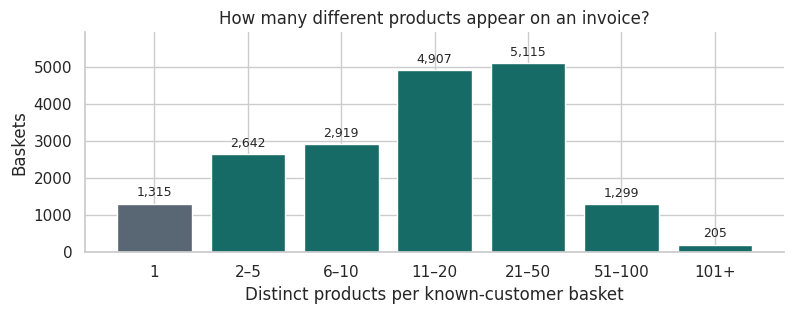

In [5]:
bands = ["1", "2–5", "6–10", "11–20", "21–50", "51–100", "101+"]
bucket = pd.cut(baskets["size"], bins=[0, 1, 5, 10, 20, 50, 100, np.inf], labels=bands)
sizes = bucket.value_counts(sort=False).reindex(bands)
fig_size, ax = plt.subplots(figsize=(8.1, 3.3))
bars = ax.bar(sizes.index, sizes.values, color=[GRAY] + [TEAL] * 6)
ax.bar_label(bars, labels=[f"{n:,}" for n in sizes.values], padding=3, fontsize=9)
ax.set(title="How many different products appear on an invoice?",
       xlabel="Distinct products per known-customer basket", ylabel="Baskets")
ax.margins(y=0.16)
sns.despine(ax=ax)
fig_size.tight_layout()
plt.show()

## 3 · Freeze the catalog and count the evidence for each pair
Use December–May for historical counts, June–August for model fitting, and September–December 9 for testing. The final period is never used to choose items, features, or thresholds. For a manageable first model, use the 500 products appearing on the most historical invoices and require three historical invoices per pair. Those are design choices, not optimized settings. Keep unknown anchors in the test denominator as misses.

In [6]:
history = baskets[baskets.date < HISTORY_END].copy()
fit_orders = baskets[baskets.date.between(HISTORY_END, FIT_END, inclusive="left")].copy()
test_orders = baskets[baskets.date >= FIT_END].copy()
parts = {"History": history, "Model fitting": fit_orders, "Held-out test": test_orders}
split_summary = pd.DataFrame([{"period": label, "from": x.date.min().date(), "through": x.date.max().date(),
                               "baskets": len(x), "multi_item": int(x["size"].ge(2).sum()),
                               "buyers": x.buyer.nunique()} for label, x in parts.items()])
display(split_summary)
assert len(baskets) == sum(map(len, parts.values()))
assert history.date.max() < fit_orders.date.min() <= fit_orders.date.max() < test_orders.date.min()
freq = history[["InvoiceNo", "items"]].explode("items").groupby("items").size().rename("basket_count")
catalog = (freq.rename_axis("item").reset_index().sort_values(["basket_count", "item"], ascending=[False, True])
           .head(CATALOG_SIZE).set_index("item").basket_count)
catalog_set = set(catalog.index)
hist_lines = sales[sales.InvoiceNo.isin(history.InvoiceNo)]
description_map = (hist_lines.dropna(subset=["Description"]).drop_duplicates("StockCode")
                   .set_index("StockCode").Description.to_dict())
def item_name(code):
    return str(description_map.get(code, code)).strip()

,period,from,through,baskets,multi_item,buyers
0,History,2010-12-01,2011-05-31,7364,6804,2716
1,Model fitting,2011-06-01,2011-08-31,3978,3679,1944
2,Held-out test,2011-09-01,2011-12-09,7060,6604,2967


In [7]:
# A buyer gets only one vote for a pair, and only if both items occurred on the SAME invoice.
def count_pairs(orders, allowed):
    invoice_counts, buyer_counts = Counter(), Counter()
    for _, customer_orders in orders.groupby("buyer", sort=False):
        seen_by_buyer = set()
        for items in customer_orders["items"]:
            present = [s for s in items if s in allowed]   # already sorted and unique
            pairs_here = list(combinations(present, 2))
            invoice_counts.update(pairs_here)
            seen_by_buyer.update(pairs_here)
        buyer_counts.update(seen_by_buyer)
    return invoice_counts, buyer_counts

# Unit check: buying A and B on different invoices is not a co-purchase.
toy = pd.DataFrame({"buyer": ["x", "x", "y", "y", "z"],
                    "items": [("A", "B"), ("A", "B"), ("A",), ("B",), ("A", "B")]})
i_check, b_check = count_pairs(toy, {"A", "B"})
assert i_check["A", "B"] == 3 and b_check["A", "B"] == 2

invoice_counts, buyer_counts = count_pairs(history, catalog_set)
pair_table = pd.DataFrame([(a, b, n, buyer_counts[(a, b)]) for (a, b), n in invoice_counts.items()
                           if n >= MIN_PAIR_INVOICES],
                          columns=["a", "b", "pair_invoices", "pair_buyers"])
assert pair_table.pair_buyers.between(1, pair_table.pair_invoices).all()
print(f"{len(pair_table):,} eligible unordered pairs; "
      f"{(pair_table.pair_invoices > pair_table.pair_buyers).mean():.1%} have more invoices than buyers.")

95,845 eligible unordered pairs; 38.8% have more invoices than buyers.


RETRO COFFEE MUGS ASSORTED  +  KNITTED UNION FLAG HOT WATER BOTTLE
20 historical invoices, 4 distinct buyers.


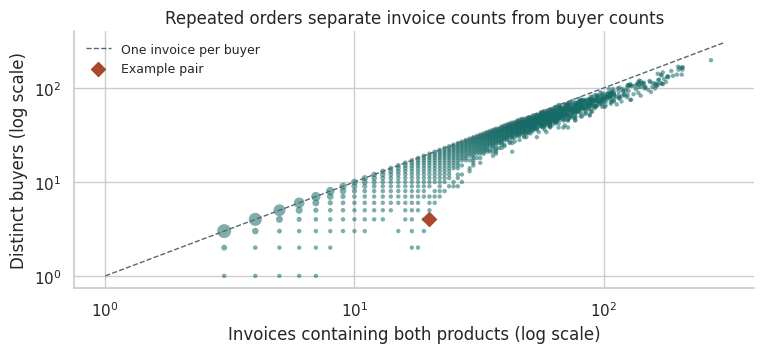

In [8]:
# Illustrate concentration: among pairs on at least 20 invoices, take the lowest buyers/invoices ratio.
contrast = (pair_table.loc[pair_table.pair_invoices.ge(20)]
            .assign(buyer_share=lambda d: d.pair_buyers / d.pair_invoices)
            .sort_values(["buyer_share", "pair_invoices", "a", "b"], ascending=[True, False, True, True])
            .iloc[0])
print(f"{item_name(contrast.a)}  +  {item_name(contrast.b)}")
print(f"{contrast.pair_invoices} historical invoices, {contrast.pair_buyers} distinct buyers.")
coords = pair_table.groupby(["pair_invoices", "pair_buyers"]).size().rename("pairs").reset_index()
fig_pair, ax = plt.subplots(figsize=(7.8, 3.7))
sns.scatterplot(data=coords, x="pair_invoices", y="pair_buyers", size="pairs", sizes=(10, 100),
                legend=False, alpha=.55, color=TEAL, linewidth=0, ax=ax)
limit = int(pair_table.pair_invoices.max() * 1.12)
ax.plot([1, limit], [1, limit], "--", color=GRAY, lw=1, label="One invoice per buyer")
ax.scatter([contrast.pair_invoices], [contrast.pair_buyers], c="#a8482c", s=50, marker="D",
           label="Example pair", zorder=3)
ax.set(xscale="log", yscale="log", xlabel="Invoices containing both products (log scale)",
       ylabel="Distinct buyers (log scale)", title="Repeated orders separate invoice counts from buyer counts")
ax.legend(frameon=False, loc="upper left", fontsize=9)
sns.despine(ax=ax)
fig_pair.tight_layout()
plt.show()

## 4 · Build the initial recommender
Turn each eligible pair in both directions: with A visible, B can be a candidate; with B visible, A can be a candidate. Match the four methods on the same candidates and use product code to break ties. For each multi-item invoice, reveal one item uniformly at random and hide the rest. We do **not** know which item was added first. Use separate fixed seeds for fitting and testing and share each query across methods.

In [9]:
graph = pd.concat([pair_table.rename(columns={"a": "anchor", "b": "candidate"}),
                   pair_table.rename(columns={"b": "anchor", "a": "candidate"})],
                  ignore_index=True)
graph["anchor_pop"] = graph.anchor.map(catalog)
graph["candidate_pop"] = graph.candidate.map(catalog)
assert not graph[["anchor", "candidate"]].duplicated().any()
assert graph.anchor.ne(graph.candidate).all()

def make_queries(orders, seed):
    rng = np.random.default_rng(seed)
    records = []
    for row in orders.loc[orders["size"] >= 2].itertuples(index=False):
        anchor = row.items[int(rng.integers(len(row.items)))]
        hidden = frozenset(row.items) - {anchor}
        records.append((row.InvoiceNo, row.buyer, anchor, hidden))
    return pd.DataFrame(records, columns=["invoice", "buyer", "anchor", "hidden"])

fit_queries = make_queries(fit_orders, SEED)
test_queries = make_queries(test_orders, SEED + 1)
assert set(fit_queries.invoice).isdisjoint(test_queries.invoice)
print(f"{len(fit_queries):,} fit queries; {len(test_queries):,} held-out queries")

3,679 fit queries; 6,604 held-out queries


**Training label:** 1 if the candidate was also purchased on the training invoice, otherwise 0. Use every eligible candidate for the sampled anchor; do not create synthetic negatives or balance the classes. Log-transform skewed counts and standardize them using the fitting examples only. The second logistic model adds just one feature: the number of different buyers who bought the pair together. Neither model receives customer IDs, price, or end-of-test information.

In [10]:
base_features = ["pair_invoices", "anchor_pop", "candidate_pop"]
buyer_features = base_features + ["pair_buyers"]
train = fit_queries[["invoice", "anchor", "hidden"]].merge(graph, on="anchor", how="inner", validate="m:m")
y_train = np.fromiter((item in actual for item, actual in zip(train.candidate, train.hidden)),
                      dtype=np.int8, count=len(train))
train_info = {"candidate_rows": len(train), "eligible_fit_queries": train.invoice.nunique(),
              "positive_rows": int(y_train.sum()), "fit_queries": len(fit_queries)}
assert 0 < y_train.sum() < len(y_train)
print(f"{len(train):,} candidate comparisons from {train.invoice.nunique():,} fitting invoices; "
      f"{y_train.mean():.2%} positive labels.")

def fit_ranker(columns):
    model = make_pipeline(FunctionTransformer(np.log1p, validate=False), StandardScaler(),
                          LogisticRegression(C=1.0, solver="lbfgs", max_iter=500, random_state=SEED))
    model.fit(train[columns], y_train)
    return model

base_model = fit_ranker(base_features)
buyer_model = fit_ranker(buyer_features)
graph["base_score"] = base_model.predict_proba(graph[base_features])[:, 1]
graph["buyer_score"] = buyer_model.predict_proba(graph[buyer_features])[:, 1]
del train

833,337 candidate comparisons from 2,046 fitting invoices; 2.57% positive labels.


In [11]:
def top_k_lists(score_column):
    ordered = graph.sort_values(["anchor", score_column, "candidate"], ascending=[True, False, True])
    top = ordered.groupby("anchor", sort=False).head(K)
    return top.groupby("anchor", sort=False).candidate.agg(tuple).to_dict()

scores = {"Invoice rule": "pair_invoices", "Buyer rule": "pair_buyers",
          "Logistic without buyers": "base_score", "Logistic with buyers": "buyer_score"}
rankings = {name: top_k_lists(column) for name, column in scores.items()}
assert all(all(anchor not in recs and len(set(recs)) == len(recs) <= K
               for anchor, recs in ranking.items()) for ranking in rankings.values())
print("Methods ready:", ", ".join(rankings))

Methods ready: Invoice rule, Buyer rule, Logistic without buyers, Logistic with buyers


**What would a shopper see?** Show the most frequent historical item for which the two counting rules choose different sets of three companions. The example is chosen before evaluating the later baskets. It illustrates a change in the displayed suggestions, not evidence that either list is better.

In [12]:
example_anchor = next(a for a in catalog.index
                      if set(rankings["Invoice rule"].get(a, ())) != set(rankings["Buyer rule"].get(a, ())))
print("Visible product:", item_name(example_anchor))
display(pd.DataFrame([[item_name(code) for code in listings[example_anchor]]
                      for listings in rankings.values()], index=list(rankings),
                     columns=["Suggestion 1", "Suggestion 2", "Suggestion 3"]))

Visible product: WHITE HANGING HEART T-LIGHT HOLDER


,Suggestion 1,Suggestion 2,Suggestion 3
Invoice rule,RED HANGING HEART T-LIGHT HOLDER,CANDLEHOLDER PINK HANGING HEART,WOODEN PICTURE FRAME WHITE FINISH
Buyer rule,RED HANGING HEART T-LIGHT HOLDER,CANDLEHOLDER PINK HANGING HEART,NATURAL SLATE HEART CHALKBOARD
Logistic without buyers,RED HANGING HEART T-LIGHT HOLDER,CANDLEHOLDER PINK HANGING HEART,WOODEN PICTURE FRAME WHITE FINISH
Logistic with buyers,RED HANGING HEART T-LIGHT HOLDER,CANDLEHOLDER PINK HANGING HEART,ASSORTED COLOUR BIRD ORNAMENT


## 5 · Score later baskets and check uncertainty
A hit is at least one actual companion in the first three suggestions. No list means no hit. Report **coverage** (any list) and **full-list coverage** (three suggestions) using all multi-item test invoices. The **buyer-average hit rate** first averages hits within each buyer, then gives each buyer equal weight; the **basket hit rate** gives each invoice equal weight. Buyer-average is the primary metric because repeat buyers motivated the question.

In [13]:
earlier_buyers = set(history.buyer) | set(fit_orders.buyer)
records = []
for q in test_queries.itertuples(index=False):
    for name, lists in rankings.items():
        recommended = lists.get(q.anchor, ())
        records.append((q.invoice, q.buyer, name, len(recommended),
                        int(not q.hidden.isdisjoint(recommended)), q.buyer in earlier_buyers))
outcomes = pd.DataFrame(records, columns=["invoice", "buyer", "method", "n_shown", "hit", "seen_before_test"])
outcomes["covered"] = outcomes.n_shown.gt(0)
outcomes["full_list"] = outcomes.n_shown.eq(K)
results = (outcomes.groupby("method").agg(test_baskets=("invoice", "size"), hits=("hit", "sum"),
                                          coverage=("covered", "mean"), full_list=("full_list", "mean"),
                                          basket_hit=("hit", "mean")).reindex(scores))
buyer_by_method = outcomes.groupby(["buyer", "method"]).hit.mean().unstack()
results["buyer_hit"] = buyer_by_method.mean()
assert results.test_baskets.eq(len(test_queries)).all() and results.coverage.nunique() == 1
assert outcomes.groupby("invoice").method.nunique().eq(len(scores)).all()
summary_display = results.copy()
for c in ["coverage", "full_list", "basket_hit", "buyer_hit"]:
    summary_display[c] = summary_display[c].map("{:.2%}".format)
display(summary_display)

# The paired bootstrap keeps all of a customer's test invoices together.
paired = buyer_by_method["Logistic with buyers"] - buyer_by_method["Logistic without buyers"]
rng = np.random.default_rng(SEED + 2)
deltas = np.array([rng.choice(paired.to_numpy(), size=len(paired), replace=True).mean()
                   for _ in range(2000)])
lo, hi = np.quantile(deltas, [.025, .975])
delta = float(paired.mean())
print(f"Adding buyer support: {100*delta:+.2f} percentage points in buyer-average hit rate "
      f"(95% paired buyer bootstrap interval: {100*lo:+.2f} to {100*hi:+.2f}; {len(paired):,} buyers).")
if lo <= 0 <= hi:
    print("The interval includes zero; this test does not establish an improvement.")
elif hi < 0:
    print("The buyer feature lowered the estimated hit rate in this holdout.")
else:
    print("The buyer feature improved the estimated hit rate in this holdout; replicate in another period.")
print(f"All four methods offered suggestions for {results.coverage.iloc[0]:.2%} of test baskets.")
best_rule = results.loc[["Buyer rule", "Invoice rule"], "buyer_hit"].idxmax()
print(f"Best simple benchmark in this test: {best_rule}, {results.loc[best_rule, 'buyer_hit']:.2%}.")

,test_baskets,hits,coverage,full_list,basket_hit,buyer_hit
method,,,,,,
Invoice rule,6604,1359,42.37%,42.37%,20.58%,19.96%
Buyer rule,6604,1372,42.37%,42.37%,20.78%,20.27%
Logistic without buyers,6604,1368,42.37%,42.37%,20.71%,20.12%
Logistic with buyers,6604,1372,42.37%,42.37%,20.78%,20.21%


Adding buyer support: +0.09 percentage points in buyer-average hit rate (95% paired buyer bootstrap interval: -0.20 to +0.39; 2,913 buyers).
The interval includes zero; this test does not establish an improvement.
All four methods offered suggestions for 42.37% of test baskets.
Best simple benchmark in this test: Buyer rule, 20.27%.


buyers buyer_average_hit
seen_before_test method                                           
False            Buyer rule                 1001            17.75%
                 Invoice rule               1001            17.20%
                 Logistic with buyers       1001            17.63%
                 Logistic without buyers    1001            17.26%
True             Buyer rule                 1912            21.59%
                 Invoice rule               1912            21.40%
                 Logistic with buyers       1912            21.56%
                 Logistic without buyers    1912            21.62%

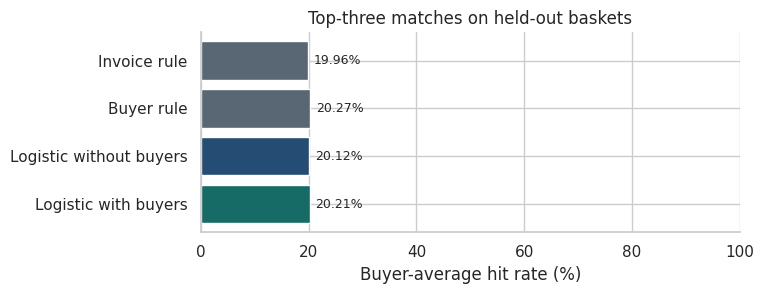

In [14]:
# Optional diagnostic: new means not observed in the identified pre-September purchases, not first-ever.
buyer_slices = (outcomes.groupby(["seen_before_test", "buyer", "method"]).hit.mean()
                .groupby(["seen_before_test", "method"]).agg(buyers="size", buyer_average_hit="mean"))
display(buyer_slices.assign(buyer_average_hit=buyer_slices.buyer_average_hit.map("{:.2%}".format)))

fig_score, ax = plt.subplots(figsize=(7.8, 3.1))
values = 100 * results.buyer_hit
bars = ax.barh(values.index, values, color=[GRAY, GRAY, BLUE, TEAL])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=4, fontsize=9)
ax.set(xlim=(0, 100), xlabel="Buyer-average hit rate (%)", title="Top-three matches on held-out baskets")
ax.invert_yaxis()
sns.despine(ax=ax)
fig_score.tight_layout()
plt.show()

### Interpreting the result
Compare the two logistic rows to isolate the extra buyer feature. Compare both against the invoice rule to decide whether training a model helped at all. The raw buyer rule is a second control: changing the counting unit and adding one model feature are different experiments. A small gap is not a deployment recommendation.

This evaluation uses completed multi-item purchases, not browsing sessions, exposures, or randomized recommendations. Dropping anonymous invoices and limiting the catalog restricts the population. A new or rare product may get no suggestions, which counts as a miss. The source reports wholesale customers, but does not label which buyers are wholesalers. A customer ID is an accounting identifier, not proof of a person's identity. Keep customer-level data out of shared outputs. A future study could vary the date window and catalog size before considering a controlled live test.

## 6 · Team collaboration and reproducibility
**Confirmed contribution:** Akhil Kamatam and Snehith Reddy discussed real-world situations they had encountered and jointly framed the problem statement.

**Next team steps:** Share this notebook in Colab, rerun it from a clean runtime, and compare the cleaning audit and held-out metric table. In the team's GitHub repository, commit the reviewed notebook and report, then link the actual issue or pull request documenting a teammate's check. One useful review is to confirm that two purchases by the same customer on different invoices are not a co-purchase. Do not commit the spreadsheet or customer-level exports. Record actual reviewers and changes after they occur.

**Sources and assistance**

- Chen, D. (2015). [Online Retail](https://doi.org/10.24432/C5BW33) [Data set]. UCI Machine Learning Repository. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- scikit-learn developers. [LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- OpenAI. [ChatGPT](https://chatgpt.com/) (Codex). Generative AI assisted with code, execution, and drafting the report. Team problem framing is credited above.